# Compare Shorescan runup with TWL&CC best-estimate forecasts

**Author:** Chelsea A. Volpano (cvolpano@gmail.com)
**Created:** 2026-11-03, with Claude Opus 5.5 (Anthropic)

**Summary.** Loads CoastCam/Shorescan runup statistics (`ss_*`) for one camera and transect, and the
USGS/NOAA Total Water Level and Coastal Change (TWL&CC) best-estimate forecast built by
`get_TWL_forecast.ipynb`. The hourly forecast is interpolated to the middle of each Shorescan capture,
observed quantities are rebuilt so they match the TWL&CC definitions, and the notebook reports
error statistics and plots for:

| Comparison | Observed (Shorescan) | Forecast (TWL&CC) |
|---|---|---|
| Total water level | 2% runup elevation, m NAVD88 | `twl` = tide + surge + R2% |
| R2% | 2% runup elevation − forecast tide + surge | `runup` |
| Wave setup | mean runup elevation − forecast tide + surge | `setup` |
| Significant swash | 4 × std of runup elevation | `swash` |
| Sea-swell / infragravity swash (new CSV only) | Shorescan spectral `ss_S_ss`, `ss_S_ig` | `incSwash`, `infragSwash` |

It also tests whether the measured beach slope explains R2% errors (Section 7) and saves the matched table.

**Datum and time.** Everything is in **m NAVD88** (TWL&CC as delivered; Birchler et al., 2024,
https://doi.org/10.1016/j.coastaleng.2024.104590). Shorescan runup elevations are assumed to be measured
directly in NAVD88 from the rectified imagery. Matching is done in **UTC**; plots use America/New_York.

**Two CSV formats.** `read_transect_nc.ipynb` was updated on 2026-11-03 to write elevations directly
(zero placeholders removed, datum-corrected `cc_*`, `t_mid_utc`, `clipped`, spectral swash). The notebook
detects that format by the `ss_ref_tide` column and uses it as is. Older CSVs are handled as below.

**Older CSVs: why their `cc_*` columns are not used.** They came from the old one-forecast-per-day
download and carry a −0.082 m LMSL→NAVD88 shift that double-shifted the data (Section 3 checks this).
`cc_tide` is `tideWindSetup`, which already includes wave setup, and the Shorescan `ss_ru_2pct`,
`ss_zrunup_*` **and `ss_twl_2pct_peaks`** columns are heights relative to it (Section 2 checks this;
despite its name, `ss_twl_2pct_peaks` is not an elevation). The notebook adds `cc_tide` back to recover the measured
elevation, so the datum error cancels, and then references runup to the forecast tide + surge.

**Change log**
- 2026-11-03: First version.
- 2026-11-03: Reads the new `read_transect_nc.ipynb` CSV format (elevations, `t_mid_utc`, `clipped`,
  sea-swell and infragravity swash), with the old format still supported. Scatter grid sized to the
  number of comparisons.

**Requires:** the Shorescan CSV, and a `*_best_estimate.csv` from `get_TWL_forecast.ipynb` run over the
Shorescan period (START_DATE 2024-10-05, END_DATE 2024-12-31).

**Background reading**
- Stockdon et al. (2023), operational TWL&CC forecasts, open access: https://doi.org/10.1038/s43247-023-00817-2
- Holman & Stanley (2007), coastal imaging (Argus/CoastCam) overview: https://doi.org/10.1016/j.coastaleng.2007.01.003
- USGS TWL&CC Forecast Viewer: https://coastal.er.usgs.gov/hurricanes/research/twlviewer/

## 1. Settings
Edit these for another transect, camera or forecast file. Transects 50 and 70 are seen by both cameras,
so the camera is set too. Available pairs are printed if the choice has no data.

In [ ]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

LOCAL_TZ = "America/New_York"
SS_FILE = Path("E:/results_11122026/processed/Shorescan_TWL_viewer_noVdatum_all-batches.csv")
TWL_FOLDER = Path("C:\\Users\\cvolp\\shorescan_processing\\DATA\\data_wl")  # where get_TWL_forecast.ipynb saves CSVs
BEST_FILE = None  # None -> newest *_best_estimate.csv in TWL_FOLDER
OUT_FOLDER = Path("E:/")
RUN_TAG = input("Enter a run tag: ")
CAMERA = "c1"
TRANSECT = 30
SAMPLE_HZ = 2.0  # Shorescan sampling rate; n_valid / SAMPLE_HZ = capture length
MAX_LEAD_HOURS = None  # e.g. 23 to drop hours covered only by older forecasts
OBS_TWL = "ss_twl_2pct_peaks"  # new CSV: 2% of runup maxima (elevation); or
#   "ss_twl_2pct" (whole series) or "ss_twl_2pct_peaks_file" (Shorescan's)
OBS_RU = "ss_twl_2pct_peaks"  # old CSV: height above cc_tide; or "ss_ru_2pct"
SLOPE_MIN = 0.005  # beta06 below this is treated as a failed slope estimate
DROP_CLIPPED = True  # leave out captures whose runup sits at a transect limit
CLIP_MIN_REPEATS = 5  # old CSV only: a limit value must repeat this often
ZOOM = ("2024-10-23", "2024-11-01")  # local dates for the zoomed plot, or None

## 2. Load Shorescan runup for one transect
**New CSV format** (has `ss_ref_tide`): elevations, `t_mid_utc`, `clipped` and spectral swash come straight
from `read_transect_nc.ipynb`, so this cell only selects columns. Everything below describes how the
**old format** is converted to the same quantities.

Each row is one capture. `dt0` is the **start** of the capture, so the forecast is matched at the middle:
`t_mid = dt0 + n_valid / SAMPLE_HZ / 2` (5 min for 1200 samples at 2 Hz).

Observed quantities, all from the runup-line elevation *z* (m NAVD88):
- `obs_twl` = `cc_tide + OBS_RU`: the 2% exceedance runup elevation. Stockdon et al. (2006) define R2%
  from individual runup maxima, so `ss_twl_2pct_peaks` is the default
  (https://doi.org/10.1016/j.coastaleng.2005.12.005). `obs_z2_series` = `cc_tide + ss_ru_2pct` is the
  2% exceedance of the whole time series instead, kept for reference.

**Check on `ss_twl_2pct_peaks`.** In this CSV it correlates with `ss_ru_2pct` at r ≈ 0.97, is never above
`ss_twl_max − cc_tide`, and is uncorrelated with the tide. So it is a runup **height** above `cc_tide`, not
an elevation, and `cc_tide` is added back like the other columns. The cell prints the check for your
transect.
- `obs_zmean`: mean runup elevation. Its height above tide + surge is the wave setup (η̄).
- `obs_S`: significant swash, 4 × the standard deviation of *z*, the time-series equivalent of Stockdon's
  4√m0.

**Coding note.** `pd.to_timedelta(..., unit="s")` turns a whole column of seconds into time spans in one
call, so the mid-times are computed without a loop.

**Clipped captures.** Many captures have a maximum runup elevation of exactly 0.000 m (37 on c1
transect 30, 61 on transect 50), and some transects repeat one upper value (1.35 m 29 times on c1
transect 70). The runup line then sits at the end of the transect or a clipping limit, so its statistics
are not real swash. These rows are flagged `clipped` (maximum exactly 0, or the transect's lowest/highest
value repeated at least `CLIP_MIN_REPEATS` times) and left out of the statistics when `DROP_CLIPPED` is
True. `zmax.map(zmax.value_counts())` looks up how often each row's value occurs, for all rows at once.

In [186]:
ss_all = pd.read_csv(SS_FILE)
sel = (ss_all["camera"] == CAMERA) & (ss_all["transect"] == TRANSECT)
if not sel.any():
    pairs = ss_all.groupby(["camera", "transect"]).size()
    raise ValueError(f"No rows for {CAMERA} transect {TRANSECT}. "
                     f"Rows per camera/transect:\n{pairs}")

ss = ss_all.loc[sel].copy()
NEW_FORMAT = "ss_ref_tide" in ss.columns

ss["t0_utc"] = pd.to_datetime(ss["dt0_utc"], utc=True, format="ISO8601")

if NEW_FORMAT:
    ss["t_mid_utc"] = pd.to_datetime(ss["t_mid_utc"], utc=True, format="ISO8601")
    ss["obs_twl"] = ss[OBS_TWL]
    ss["obs_z2_series"] = ss["ss_twl_2pct"]
    ss["obs_S"] = ss["ss_S"]
    ss["obs_S_ss"], ss["obs_S_ig"] = ss["ss_S_ss"], ss["ss_S_ig"]
    ss["clipped"] = ss["clipped"].astype(bool)
else:
    ss["t_mid_utc"] = ss["t0_utc"] + pd.to_timedelta(
        ss["n_valid"] / SAMPLE_HZ / 2, unit="s")
    # Measured runup-line elevations, m NAVD88. ss_ru_2pct was computed as
    # z - cc_tide, so adding cc_tide back recovers z and cancels any cc_ error.
    ss["obs_twl"] = ss["cc_tide"] + ss[OBS_RU]
    ss["obs_z2_series"] = ss["cc_tide"] + ss["ss_ru_2pct"]
    ss["obs_S"] = 4 * ss["ss_twl_std"]
    # value_counts gives how often each max elevation occurs; map() looks
    # that count up for every row at once.
    zmax = ss["ss_twl_max"].round(3)
    repeats = zmax.map(zmax.value_counts())
    at_limit = (zmax == 0) | zmax.isin([zmax.min(), zmax.max()])
    ss["clipped"] = at_limit & (repeats >= CLIP_MIN_REPEATS)

ss["t_mid_utc"] = ss["t_mid_utc"].dt.as_unit("ns")  # see Section 3 note
ss = ss.sort_values("t_mid_utc").drop_duplicates("t_mid_utc", ignore_index=True)
ss["obs_zmean"] = ss["ss_twl_mean"]
ss["obs_zmax"] = ss["ss_twl_max"]
ss["slope_ok"] = ss["beta06"] >= SLOPE_MIN

print(f"{'New' if NEW_FORMAT else 'Old'} CSV format. "
      f"{CAMERA} transect {TRANSECT}: {len(ss)} captures, "
      f"{ss['t_mid_utc'].min():%Y-%m-%d} to {ss['t_mid_utc'].max():%Y-%m-%d} UTC; "
      f"{ss['slope_ok'].mean():.0%} have beta06 >= {SLOPE_MIN}; "
      f"{ss['clipped'].sum()} flagged clipped")
# Old format: a height above cc_tide tracks ss_ru_2pct; an elevation would
# track the tide. The new format should show r close to 1 with the tide.
print(f"r(ss_twl_2pct_peaks, cc_tide) = "
      f"{ss['ss_twl_2pct_peaks'].corr(ss['cc_tide']):.2f}")

New CSV format. c1 transect 30: 1890 captures, 2024-10-05 to 2025-04-01 UTC; 41% have beta06 >= 0.005; 532 flagged clipped
r(ss_twl_2pct_peaks, cc_tide) = 0.54


## 3. Load the TWL&CC best estimate
`keep_default_na=False, na_values=[""]` keeps the text "None" in `predictedImpact` (pandas would otherwise
read it as missing) while gap rows, written as empty cells, still become NaN.

`swl` is the forecast still water level: tide + surge without wave setup, `tideWindSetup − setup`.
R2% and setup in TWL&CC are both heights above it.

If `MAX_LEAD_HOURS` is set, values from longer leads are blanked (set to NaN) rather than dropped, so the
hourly grid stays regular.

**Time resolution.** Recent pandas versions store each datetime column at whatever resolution it was
parsed with (seconds, microseconds or nanoseconds). `merge_asof` refuses to join columns with different
resolutions, so both time columns are converted with `.dt.as_unit("ns")`.

In [187]:
if BEST_FILE is None:
    found = sorted(TWL_FOLDER.glob("*_best_estimate.csv"),
                   key=lambda p: p.stat().st_mtime)
    if not found:
        raise FileNotFoundError(f"No *_best_estimate.csv in {TWL_FOLDER}; "
                                "run get_TWL_forecast.ipynb first.")
    BEST_FILE = found[-1]

be = pd.read_csv(BEST_FILE, keep_default_na=False, na_values=[""])
# pandas 3 picks a time resolution (s, ms, us, ns) per column; merges need
# both sides to match, so every time column is set to nanoseconds.
be["valid_time_utc"] = pd.to_datetime(be["valid_time_utc"], utc=True).dt.as_unit("ns")
be = be.sort_values("valid_time_utc", ignore_index=True)
num_cols = be.select_dtypes("number").columns.drop("lead_hours")
if MAX_LEAD_HOURS is not None:
    be.loc[be["lead_hours"] > MAX_LEAD_HOURS, num_cols] = np.nan
be["swl"] = be["tideWindSetup"] - be["setup"]

in_range = ss["t_mid_utc"].between(be["valid_time_utc"].min(),
                                   be["valid_time_utc"].max())
print(f"Forecast file: {BEST_FILE.name}")
print(f"Forecast covers {be['valid_time_utc'].min():%Y-%m-%d %H:%M} to "
      f"{be['valid_time_utc'].max():%Y-%m-%d %H:%M} UTC; "
      f"{in_range.sum()} of {len(ss)} captures fall inside it.")
if not in_range.all():
    print("NOTE: re-run get_TWL_forecast.ipynb with START_DATE/END_DATE "
          "covering the Shorescan period to compare every capture.")

Forecast file: Boston,_MA_1548_20241004-20250320_best_estimate.csv
Forecast covers 2024-10-05 00:00 to 2025-03-20 12:00 UTC; 1761 of 1890 captures fall inside it.
NOTE: re-run get_TWL_forecast.ipynb with START_DATE/END_DATE covering the Shorescan period to compare every capture.


## 4. Match the forecast to each capture
The forecast is hourly and the captures are every 30 min, so forecast values are **linearly interpolated**
to each capture's mid-time. (The old CSV used the value at the start of the hour instead, which lags the
tide by up to 30 min, up to ~0.4 m on a rising tide here.)

**Coding note: `np.interp`.** `np.interp(x, xp, fp)` interpolates a whole array of new times `x` against
known times `xp` in compiled code, which is much faster than looping over rows. It needs plain numbers, so
times are converted to seconds since 1970 first. Two edge cases are handled on purpose:
- `left=np.nan, right=np.nan`: captures outside the forecast period get NaN instead of the end value.
- A NaN in either neighbouring hour gives NaN, so captures next to a forecast gap are not filled.

Peak period `pp` and `lead_hours` are taken from the **nearest** hour (`pd.merge_asof`) instead: `pp` can
jump between swell and wind sea, and interpolating across that jump gives a period neither forecast had.

In [188]:
EPOCH = pd.Timestamp("1970-01-01", tz="UTC")


def to_seconds(times: pd.Series) -> np.ndarray:
    """Tz-aware datetimes -> float seconds since 1970 (any time resolution)."""
    return ((times - EPOCH) / pd.Timedelta("1s")).to_numpy()


INTERP_VARS = ["twl", "twl05", "twl95", "tideWindSetup", "swl", "setup",
               "runup", "runup05", "runup95", "swash", "incSwash",
               "infragSwash", "hs"]
x_new, x_fc = to_seconds(ss["t_mid_utc"]), to_seconds(be["valid_time_utc"])

# Dictionary comprehension: one interpolated array per variable, built into
# a DataFrame in a single step.
fc = pd.DataFrame({f"fc_{v}": np.interp(x_new, x_fc, be[v].to_numpy(float),
                                        left=np.nan, right=np.nan)
                   for v in INTERP_VARS if v in be})

nearest = pd.merge_asof(
    ss[["t_mid_utc"]], be[["valid_time_utc", "pp", "lead_hours"]],
    left_on="t_mid_utc", right_on="valid_time_utc", direction="nearest",
    tolerance=pd.Timedelta("30min"))
fc["fc_pp"] = nearest["pp"].to_numpy()
fc["fc_lead_hours"] = nearest["lead_hours"].to_numpy()

m = pd.concat([ss, fc], axis=1)
m["t_mid_local"] = m["t_mid_utc"].dt.tz_convert(LOCAL_TZ)

# Observed R2% and setup above the FORECAST tide + surge (see caveats).
m["obs_R2"] = m["obs_twl"] - m["fc_swl"]
m["obs_setup"] = m["obs_zmean"] - m["fc_swl"]
m["matched"] = m["fc_twl"].notna()
m["use"] = m["matched"] & ~(m["clipped"] & DROP_CLIPPED)
print(f"Matched {m['matched'].sum()} of {len(m)} captures to a forecast; "
      f"{m['use'].sum()} used in the statistics.")
mu = m[m["use"]]  # rows used for statistics and scatter plots

Matched 1761 of 1890 captures to a forecast; 1347 used in the statistics.


### 4a. Check the `cc_*` columns
Two quick checks on the forecast values stored in the Shorescan files, using the matched rows:
1. **Datum shift.** `cc_twl` minus the forecast `twl` should be about −0.08 m in an old-format CSV (old VDatum
   shift still there) and about 0 in a new-format CSV (corrected). It is not exactly constant because the best estimate uses newer forecast issues and interpolated
   times, while the old CSV used the 00:00 UTC issue and the start-of-hour value.
2. **`cc_tide` includes setup.** `cc_twl − cc_tide − cc_ru_2pct` should equal −`setup`.

In [189]:
mm = m[m["matched"]]
shift = mm["cc_twl"] - mm["fc_twl"]
setup_check = (mm["cc_twl"] - mm["cc_tide"] - mm["cc_ru_2pct"]) + mm["fc_setup"]
print(f"cc_twl - forecast twl: median {shift.median():+.3f} m "
      f"(IQR {shift.quantile(.25):+.3f} to {shift.quantile(.75):+.3f})")
print(f"cc_twl - cc_tide - cc_ru_2pct + setup: median "
      f"{setup_check.median():+.3f} m (near 0 means cc_tide includes setup)")

cc_twl - forecast twl: median +0.008 m (IQR -0.052 to +0.079)
cc_twl - cc_tide - cc_ru_2pct + setup: median -0.001 m (near 0 means cc_tide includes setup)


## 5. Error statistics
For each pair, error = forecast − observed, so a positive bias means the forecast is too high.
- **bias**: mean error. **RMSE**: typical size of the error. **uRMSE**: RMSE after removing the bias,
  i.e. the scatter (RMSE² = bias² + uRMSE²).
- **r**: Pearson correlation; whether the timing and shape agree regardless of offset.
- **slope**: least-squares slope of forecast on observed; < 1 means the forecast under-predicts large events.
- Only rows with `use = True` (matched, and not clipped if `DROP_CLIPPED`) are included.
- **in 5–95%**: share of observations inside the forecast's 90% interval. About 90% means the interval is
  well calibrated.

**Coding note.** `skill()` works on whole columns at once: each statistic is one array operation, and
`np.polyfit` fits the line in compiled code. The table is built by applying it to a dictionary of column
pairs, so adding a comparison is one extra line in `PAIRS`.

In [190]:
# name: (observed column, forecast column, forecast 5% col, forecast 95% col)
PAIRS = {
    "TWL (m NAVD88)": ("obs_twl", "fc_twl", "fc_twl05", "fc_twl95"),
    "R2% (m)": ("obs_R2", "fc_runup", "fc_runup05", "fc_runup95"),
    "Setup (m)": ("obs_setup", "fc_setup", None, None),
    "Swash S (m)": ("obs_S", "fc_swash", None, None),
}
if NEW_FORMAT:  # Shorescan spectral swash by frequency band
    PAIRS["Sea-swell swash (m)"] = ("obs_S_ss", "fc_incSwash", None, None)
    PAIRS["Infragravity swash (m)"] = ("obs_S_ig", "fc_infragSwash", None, None)


def skill(df: pd.DataFrame, obs: str, fc: str, lo=None, hi=None) -> pd.Series:
    """Bias, RMSE, uRMSE, r, slope and interval coverage of fc vs obs."""
    d = df[[obs, fc] + [c for c in (lo, hi) if c]].dropna()
    err = d[fc] - d[obs]
    out = {"n": len(d), "bias": err.mean(), "rmse": np.sqrt((err**2).mean()),
           "urmse": err.std(ddof=0), "r": d[obs].corr(d[fc]),
           "slope": np.polyfit(d[obs], d[fc], 1)[0] if len(d) > 2 else np.nan}
    if lo:
        out["in 5-95%"] = d[obs].between(d[lo], d[hi]).mean()
    return pd.Series(out)


STAT_COLS = ["n", "bias", "rmse", "urmse", "r", "slope", "in 5-95%"]


stats = pd.DataFrame({name: skill(mu, *cols)
                      for name, cols in PAIRS.items()}).T[STAT_COLS]
stats.round(3)

,n,bias,rmse,urmse,r,slope,in 5-95%
TWL (m NAVD88),1340.0,-0.183,1.000,0.983,0.567,0.388,0.319
R2% (m),1340.0,-0.183,1.000,0.983,0.251,0.081,0.321
Setup (m),1347.0,0.104,0.760,0.753,0.157,0.025,NaN
Swash S (m),1347.0,-0.360,0.789,0.702,0.321,0.155,NaN
Sea-swell swash (m),1347.0,-0.333,0.558,0.448,0.321,0.183,NaN
Infragravity swash (m),1347.0,-0.150,0.533,0.511,0.308,0.137,NaN


### 5a. Error by forecast lead time
`pd.cut` assigns every row to a lead-time bin in one call; `groupby` then computes the statistics per bin.
With every forecast issue downloaded, most captures should be in the 0–11 h bins.

In [191]:
lead_bins = pd.cut(mu["fc_lead_hours"].astype(float), [0, 6, 12, 24, 48, 145],
                   right=False, labels=["0-5 h", "6-11 h", "12-23 h",
                                        "24-47 h", "48-144 h"])
by_lead = (mu.groupby(lead_bins, observed=True)
             .apply(lambda g: skill(g, *PAIRS["TWL (m NAVD88)"]),
                    include_groups=False))
by_lead.round(3)

,n,bias,rmse,urmse,r,slope,in 5-95%
fc_lead_hours,,,,,,,
0-5 h,773.0,-0.257,1.159,1.130,0.569,0.345,0.318
6-11 h,530.0,-0.137,0.705,0.692,0.633,0.601,0.323
12-23 h,20.0,0.403,0.823,0.718,0.640,0.257,0.500
24-47 h,4.0,0.562,0.681,0.384,0.963,0.241,0.250
48-144 h,13.0,1.258,1.323,0.410,0.870,0.347,0.000


## 6. Plots
### 6a. Time series
Top: observed 2% runup elevation and mean runup elevation (dots) against the forecast TWL, its 5–95% range
and the forecast tide + surge. Bottom: observed and forecast R2%. The second figure zooms to `ZOOM`.
Times are local; `DateFormatter(..., tz=LOCAL_TZ)` is needed because matplotlib otherwise labels
tz-aware times in UTC.

**Coding note.** The plotting is wrapped in a function so the full period and the zoom use the same code.
Forecast lines are drawn from the hourly `be` table, not the matched rows, so they show the full forecast
between captures.

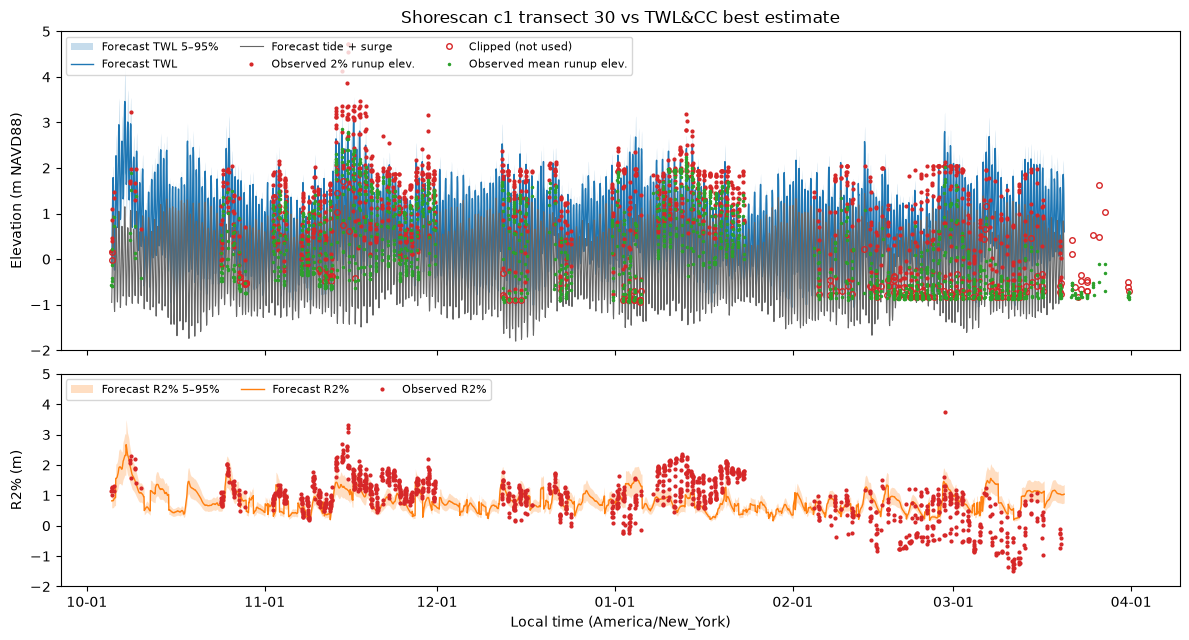

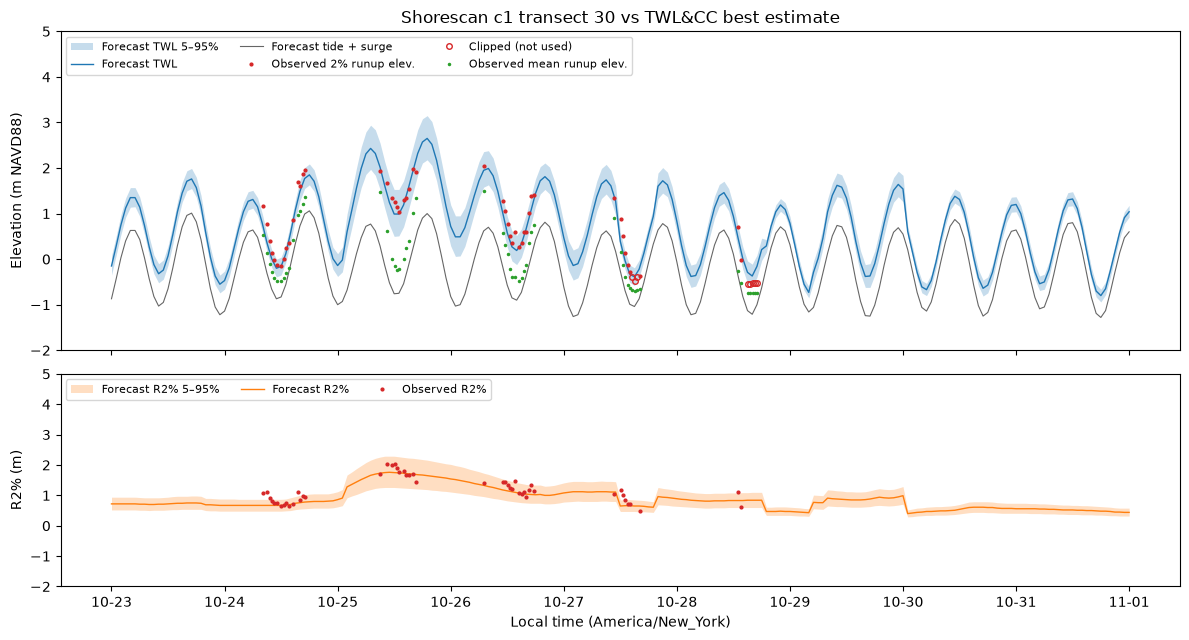

In [192]:
def plot_series(start=None, end=None):
    """Observed vs forecast TWL and R2% between two local dates."""
    t0 = pd.Timestamp(start, tz=LOCAL_TZ) if start else m["t_mid_local"].min()
    t1 = pd.Timestamp(end, tz=LOCAL_TZ) if end else m["t_mid_local"].max()
    f = be[be["valid_time_utc"].between(t0, t1)]
    o = m[m["t_mid_local"].between(t0, t1)]
    tf = f["valid_time_utc"].dt.tz_convert(LOCAL_TZ)

    fig, (ax, ax2) = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True,
                                  gridspec_kw={"height_ratios": [3, 2]})
    ax.fill_between(tf, f["twl05"], f["twl95"], color="C0", alpha=0.25,
                    lw=0, label="Forecast TWL 5–95%")
    ax.plot(tf, f["twl"], color="C0", lw=1, label="Forecast TWL")
    ax.plot(tf, f["swl"], color="0.4", lw=0.8, label="Forecast tide + surge")
    ax.plot(o["t_mid_local"], o["obs_twl"].where(o["use"]), ".", color="C3",
            ms=4, label="Observed 2% runup elev.")
    ax.plot(o["t_mid_local"], o["obs_twl"].where(o["clipped"]), "o",
            mfc="none", color="C3", ms=4, label="Clipped (not used)")
    ax.plot(o["t_mid_local"], o["obs_zmean"], ".", color="C2", ms=3,
            label="Observed mean runup elev.")
    ax.set_ylabel("Elevation (m NAVD88)")
    ax.set_title(f"Shorescan {CAMERA} transect {TRANSECT} vs TWL&CC best estimate")
    ax.legend(loc="upper left", ncol=3, fontsize=8)
    ax.set_ylim([-2,5])    
    ax2.fill_between(tf, f["runup05"], f["runup95"], color="C1", alpha=0.25,
                     lw=0, label="Forecast R2% 5–95%")
    ax2.plot(tf, f["runup"], color="C1", lw=1, label="Forecast R2%")
    ax2.plot(o["t_mid_local"], o["obs_R2"].where(o["use"]), ".", color="C3", ms=4,
             label="Observed R2%")
    ax2.set_ylabel("R2% (m)")
    ax2.set_xlabel(f"Local time ({LOCAL_TZ})")
    ax2.legend(loc="upper left", ncol=3, fontsize=8)
    ax2.set_ylim([-2,5])
    ax2.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d", tz=LOCAL_TZ))
    fig.tight_layout()
    plt.savefig(OUT_FOLDER / f"TWL-R2_comparison_series_{CAMERA}_{TRANSECT}.png", dpi=150)
    plt.show()


plot_series()
if ZOOM:
    plot_series(*ZOOM)


### 6b. Observed vs forecast (1:1)
Only rows used in the statistics are shown. Points on the dashed line are perfect forecasts; colour
shows wave height. The text box repeats the
statistics from Section 5.

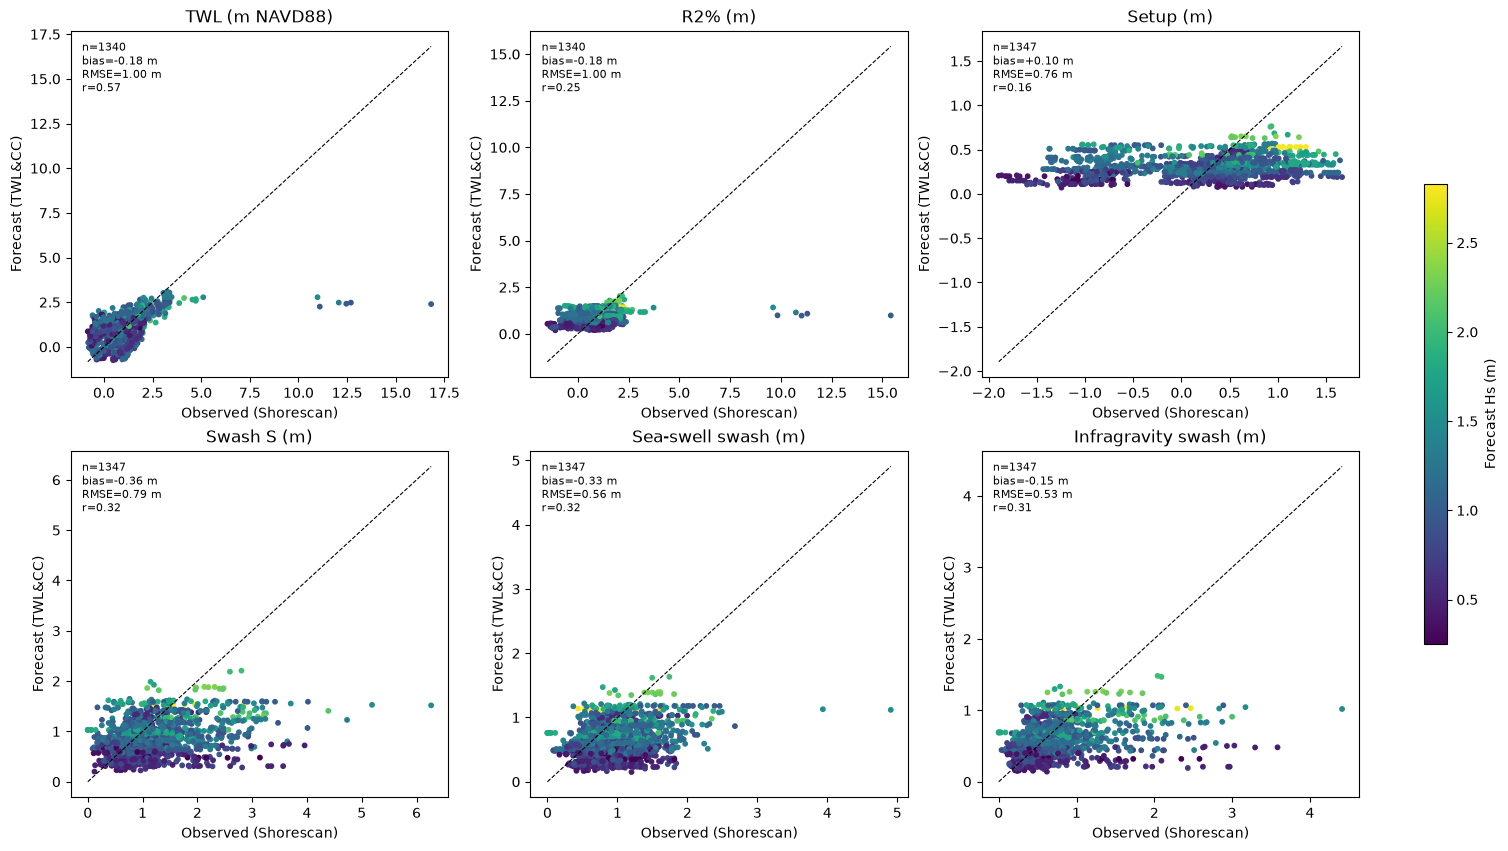

In [193]:
ncol = 3 if len(PAIRS) > 4 else 2
nrow = -(-len(PAIRS) // ncol)  # ceiling division
fig, axes = plt.subplots(nrow, ncol, figsize=(5 * ncol, 4.2 * nrow),
                         layout="constrained", squeeze=False)
for ax in axes.flat[len(PAIRS):]:
    ax.set_visible(False)  # spare panels
for ax, (name, (obs, fc, _, _)) in zip(axes.flat, PAIRS.items()):
    d = mu[[obs, fc, "fc_hs"]].dropna()
    if d.empty:
        ax.set_title(f"{name}: no data")
        continue
    sc = ax.scatter(d[obs], d[fc], c=d["fc_hs"], s=10, cmap="viridis")
    lims = [np.nanmin(d[[obs, fc]].to_numpy()), np.nanmax(d[[obs, fc]].to_numpy())]
    ax.plot(lims, lims, "k--", lw=0.8)
    s = stats.loc[name]
    ax.text(0.03, 0.97, f"n={s.n:.0f}\nbias={s.bias:+.2f} m\nRMSE={s.rmse:.2f} m"
            f"\nr={s.r:.2f}", transform=ax.transAxes, va="top", fontsize=8,
            bbox={"fc": "white", "alpha": 0.8, "lw": 0})
    ax.set(title=name, xlabel="Observed (Shorescan)", ylabel="Forecast (TWL&CC)")
fig.colorbar(sc, ax=axes, label="Forecast Hs (m)", shrink=0.6)
plt.savefig(OUT_FOLDER / f"TWL-R2_comparison_scatter_{CAMERA}_{TRANSECT}.png", dpi=150)
plt.show()

### 6c. What drives the error?
TWL error (forecast − observed) against forecast Hs, forecast Tp and the measured beach slope (only rows
with `beta06 >= SLOPE_MIN`). A trend with Hs or Tp points to the runup term; a constant offset at all wave
heights points to the tide/surge forecast or the image rectification.

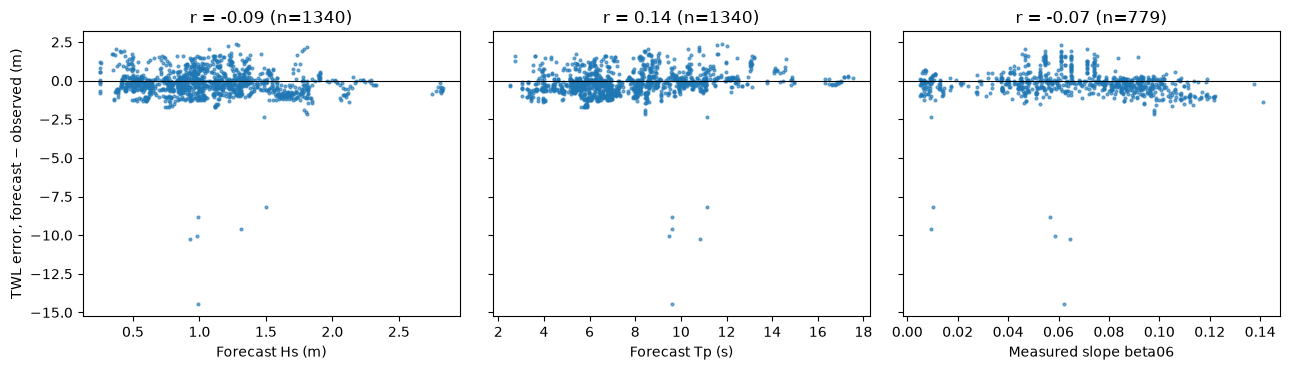

In [194]:
m["err_twl"] = m["fc_twl"] - m["obs_twl"]
m["err_R2"] = m["fc_runup"] - m["obs_R2"]
mu = m[m["use"]]
drivers = [("fc_hs", "Forecast Hs (m)", mu.index),
           ("fc_pp", "Forecast Tp (s)", mu.index),
           ("beta06", "Measured slope beta06", mu.index[mu["slope_ok"]])]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, (col, label, keep) in zip(axes, drivers):
    d = mu.loc[keep, [col, "err_twl"]].dropna()
    ax.plot(d[col], d["err_twl"], ".", ms=4, alpha=0.6)
    ax.axhline(0, color="k", lw=0.8)
    ax.set(xlabel=label, title=f"r = {d[col].corr(d['err_twl']):.2f} (n={len(d)})")
axes[0].set_ylabel("TWL error, forecast − observed (m)")
fig.tight_layout()
plt.savefig(OUT_FOLDER / f"TWL-R2_comparison_drivers_{CAMERA}_{TRANSECT}_{RUN_TAG}.png", dpi=150)
plt.show()

## 7. Does the measured slope explain the R2% error?
TWL&CC computes R2% with the Stockdon et al. (2006) parameterisation and a slope from lidar surveys.
Here R2% is recomputed from the **forecast waves** and the **measured slope** (`beta06`, assumed to be the
foreshore slope tan β):

$$R_{2\%} = 1.1\left(0.35\,\beta\sqrt{H_0 L_0} + \tfrac{1}{2}\sqrt{H_0 L_0\,(0.563\,\beta^2 + 0.004)}\right),
\qquad L_0 = \frac{g T_p^2}{2\pi}$$

If the skill improves, the slope used by the forecast is a main error source at this site.
Caveats: `hs` is treated as the deep-water height H0, which may not match the wave input the model uses,
and only rows with a valid slope are used.

**Coding note.** The formula is written once as a function of arrays, so it computes every row at once.

In [195]:
G = 9.81


def stockdon_r2(h0, tp, beta):
    """R2% from Stockdon et al. (2006), eq. 19; works on whole arrays."""
    hl = h0 * G * tp**2 / (2 * np.pi)
    return 1.1 * (0.35 * beta * np.sqrt(hl)
                  + 0.5 * np.sqrt(hl * (0.563 * beta**2 + 0.004)))


m["sd_R2_obs_slope"] = np.where(m["slope_ok"],
                                stockdon_r2(m["fc_hs"], m["fc_pp"], m["beta06"]),
                                np.nan)
ok = m["use"] & m["slope_ok"]
pd.DataFrame({
    "TWL&CC R2%": skill(m[ok], "obs_R2", "fc_runup"),
    "Stockdon + measured slope": skill(m[ok], "obs_R2", "sd_R2_obs_slope"),
}).T.round(3)

,n,bias,rmse,urmse,r,slope
TWL&CC R2%,779.0,-0.215,1.154,1.133,0.310,0.086
Stockdon + measured slope,779.0,-0.365,1.204,1.148,0.271,0.063


## 8. Save the matched table
One row per capture with the Shorescan statistics, the matched forecast (`fc_*`), the rebuilt observed
quantities (`obs_*`) and the errors. Times are written with explicit UTC offsets. A short README describes
the columns.

In [196]:
OUT_FOLDER.mkdir(parents=True, exist_ok=True)
stem = f"shorescan_{CAMERA}_t{TRANSECT}_vs_twlcc"
front = ["t_mid_local", "t_mid_utc", "fc_lead_hours", "use"]
m[front + [c for c in m.columns if c not in front]].to_csv(
    OUT_FOLDER / f"{stem}.csv", index=False)
stats.to_csv(OUT_FOLDER / f"{stem}_stats.csv")

(OUT_FOLDER / f"{stem}_README.txt").write_text(f"""\
Shorescan ({CAMERA}, transect {TRANSECT}) vs TWL&CC best estimate
Created {pd.Timestamp.now(tz=LOCAL_TZ):%Y-%m-%d} by compare_shorescan_twl.ipynb
Forecast file: {BEST_FILE.name}

Elevations m NAVD88; heights (R2, setup, swash) in m.
t_mid_*        middle of the capture (dt0 + n_valid / {SAMPLE_HZ} Hz / 2)
fc_*           forecast interpolated to t_mid (fc_pp, fc_lead_hours: nearest hour)
clipped        runup at a transect limit (max exactly 0 or a repeated end value)
use            matched to a forecast and not clipped (rows in the statistics)
fc_swl         forecast tide + surge = tideWindSetup - setup
obs_twl        2% exceedance runup elevation ({OBS_TWL if NEW_FORMAT else 'cc_tide + ' + OBS_RU})
obs_z2_series  cc_tide + ss_ru_2pct: 2% exceedance of the whole time series
obs_zmean      mean runup elevation (ss_twl_mean)
obs_R2         obs_twl - fc_swl      obs_setup  obs_zmean - fc_swl
obs_S          4 * std of runup elevation (significant swash)
obs_S_ss/_ig   Shorescan spectral sea-swell / infragravity swash (new CSV only)
err_*          forecast - observed
cc_* columns   forecast stored in the Shorescan files (old 00:00 UTC issue);
               datum-corrected in new-format CSVs, -0.082 m in old ones.
""")
print(f"Saved {stem}.csv, _stats.csv and _README.txt to {OUT_FOLDER.resolve()}")

Saved shorescan_c1_t30_vs_twlcc.csv, _stats.csv and _README.txt to E:\


## Caveats
- **Observed R2% and setup use the forecast tide + surge** as their reference, so tide and surge errors
  appear in them. The TWL comparison (Section 5, first row) does not have this problem, because both sides
  are elevations. A nearby NOAA tide gauge would give an independent still water level.
- **Image-derived elevations** depend on the beach profile used to rectify the images. If the beach has
  changed since that survey, runup elevations will be biased, mostly during storms.
- **Clipped runup.** Captures whose runup sits at a transect limit are flagged and, by default, dropped
  (Section 2). Check the flag on new transects; a limit that repeats fewer than `CLIP_MIN_REPEATS` times
  is not caught.
- **Elevations are quantised** (many `ss_twl_max` values step by 0.125 m), which limits how well small
  differences can be resolved.
- **Incident vs infragravity swash** (`incSwash`, `infragSwash`) can't be compared without the runup
  spectra; only the total swash S is compared here.
- **Daylight only.** Captures run about 06:00–17:00 local, so night-time high tides are not sampled.